# California Housing: Data Exploration

Goal: understand the features, target variable, data quality, distributions, relationships, and possible problems before building regression models.

Questions:
- What does each feature represent?
- Which features are related to house value?
- Are there missing values or outliers?
- Which features may require scaling or transformation?
- Does a linear relationship seem reasonable?

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.shape

(20640, 9)

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Datasetcontains :
<li>20k+ records of houses.</li>
<li>6 useful input columns/features( total 8 )</li>
<li>Target range is (500k$ - 200k$) = 300k$</li>
<li>features with very different scale: Population</li>
<li>features with Suspicious minimum or maximum values: AveRooms,AveBedrms,AveOccup</li>


In [6]:
df.isna().sum() # no missing values

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [7]:
df.duplicated().sum() # no duplicate rows

np.int64(0)

In [8]:
df.nunique().sort_values()

HouseAge          52
Longitude        844
Latitude         862
MedHouseVal     3842
Population      3888
MedInc         12928
AveBedrms      14233
AveOccup       18841
AveRooms       19392
dtype: int64

In [9]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [10]:
df.corr() #columns 'AveRooms' and 'AveBedrms' are highly correlated.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


In [11]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


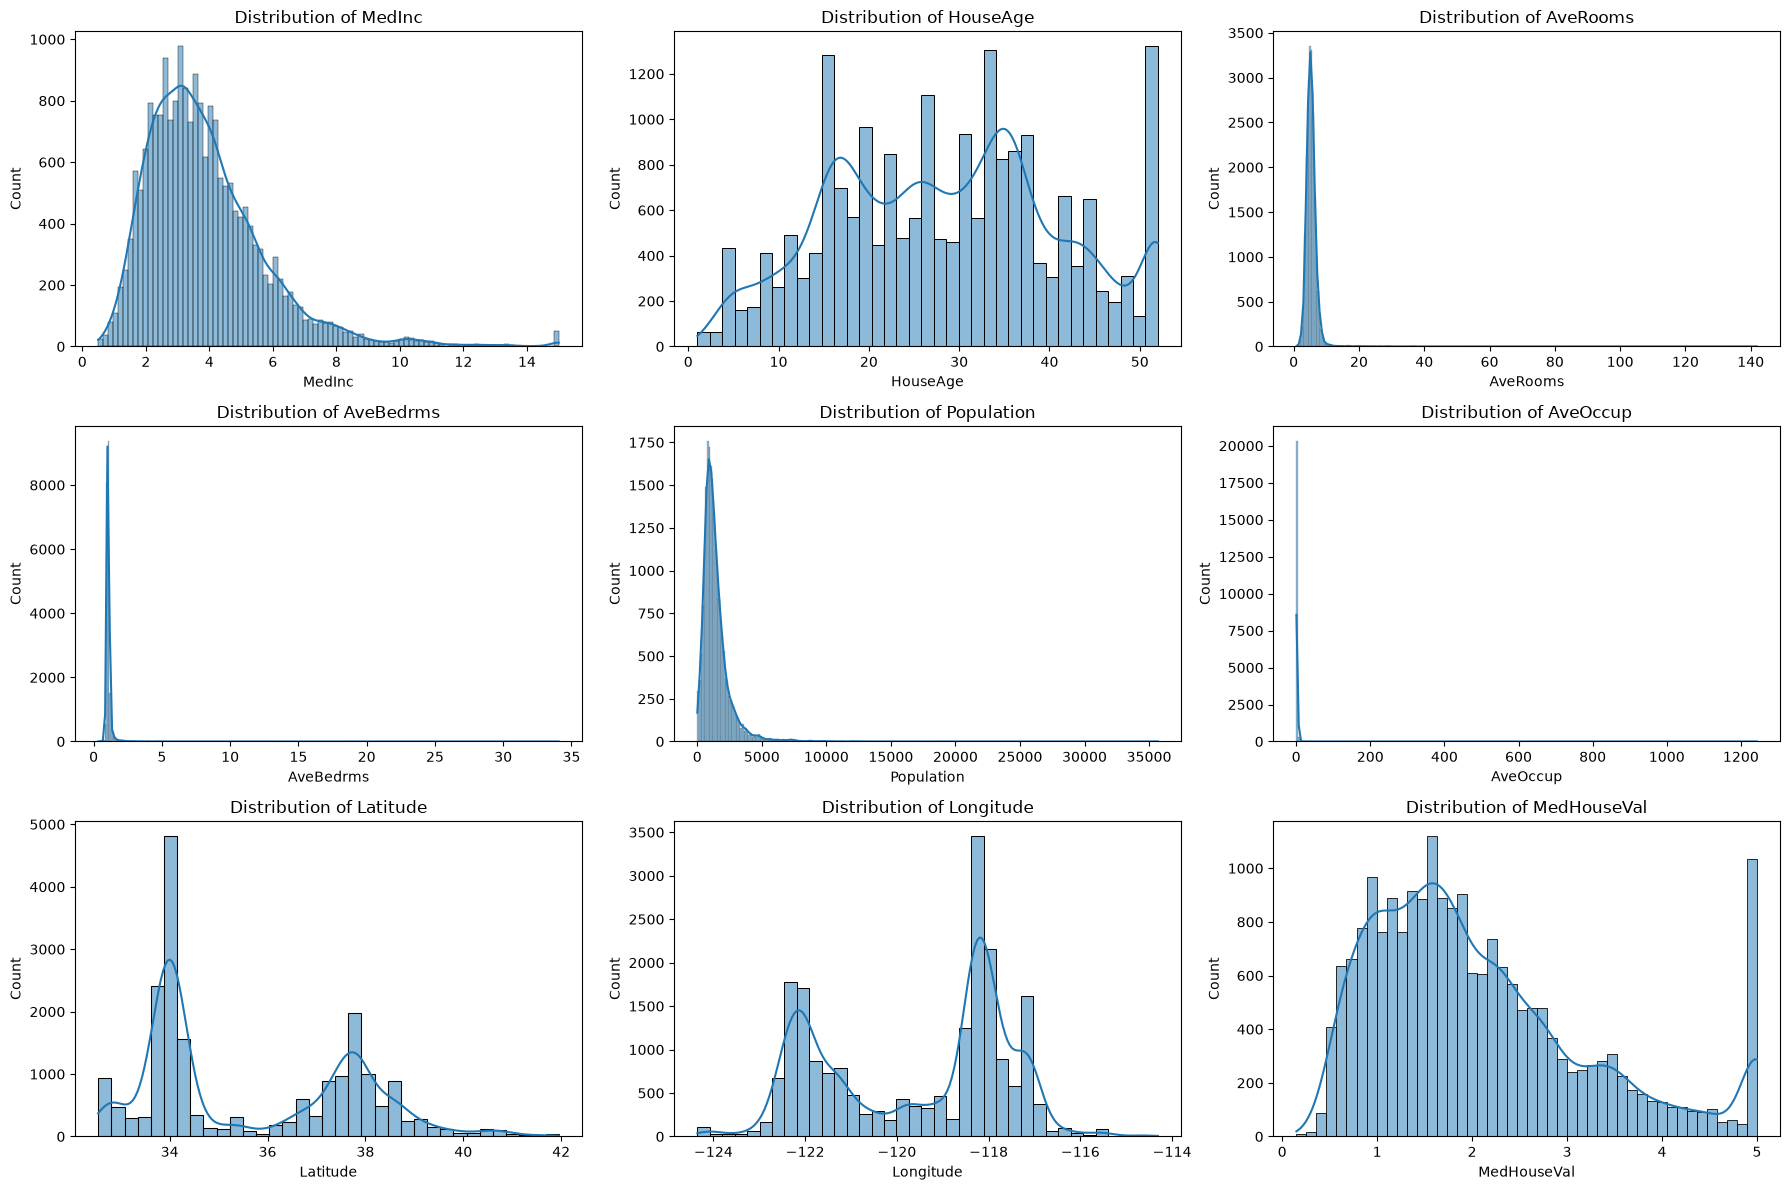

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.ravel()

for ax, column in zip(axes, df.columns):
    sns.histplot(df[column], kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

MedInc and MedHouseVal

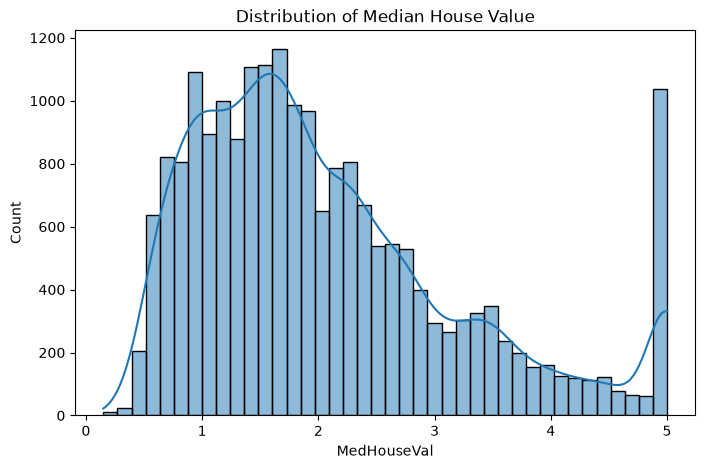

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.show()

In [14]:
df['MedHouseVal'].describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

In [15]:
(df['MedHouseVal'] >= 5.0).mean() * 100 # checking the percentage of values capped at 5 in target column

np.float64(4.8062015503875966)

In [16]:
df.iloc[:,-1]

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

# Checking model performance before Preprocessing.

In [17]:
X = df.drop(columns=['MedHouseVal'])
y = df.iloc[:,-1]

In [18]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
lr = LinearRegression()

In [20]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6013853272055154

In [38]:
df_uncapped = df[df['MedHouseVal'] < 5.0].copy()
df_uncapped.shape


(19648, 9)

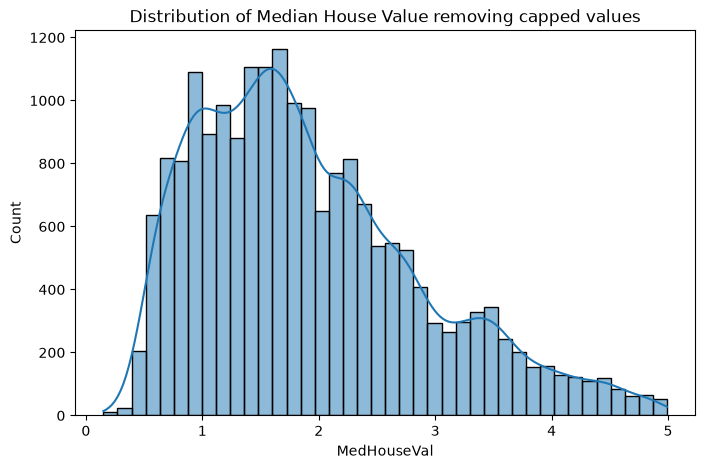

In [39]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_uncapped, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Value removing capped values")
plt.show()

In [42]:
feature_columns = df.columns.drop("MedHouseVal")

train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.2,
    random_state=2
)

# Model 1: trained on all original training rows
model_all = LinearRegression()
model_all.fit(
    df.loc[train_indices, feature_columns],
    df.loc[train_indices, "MedHouseVal"]
)

# Model 2: trained only on uncapped rows from the same training set
uncapped_train_indices = train_indices[
    df.loc[train_indices, "MedHouseVal"] < 5.0
]

model_uncapped = LinearRegression()
model_uncapped.fit(
    df.loc[uncapped_train_indices, feature_columns],
    df.loc[uncapped_train_indices, "MedHouseVal"]
)

# Both models evaluated on the exact same original test set
X_test_common = df.loc[test_indices, feature_columns]
y_test_common = df.loc[test_indices, "MedHouseVal"]

r2_all = r2_score(
    y_test_common,
    model_all.predict(X_test_common)
)

r2_uncapped = r2_score(
    y_test_common,
    model_uncapped.predict(X_test_common)
)

print("R², model trained on all rows:", r2_all)
print("R², model trained without capped training rows:", r2_uncapped)

R², model trained on all rows: 0.6013853272055154
R², model trained without capped training rows: 0.5959199044689703


In [43]:
uncapped_test_indices = test_indices[
    df.loc[test_indices, "MedHouseVal"] < 5.0
]

X_uncapped_test = df.loc[uncapped_test_indices, feature_columns]
y_uncapped_test = df.loc[uncapped_test_indices, "MedHouseVal"]

print(
    "All-row model on uncapped test rows:",
    r2_score(y_uncapped_test, model_all.predict(X_uncapped_test))
)

print(
    "Uncapped model on uncapped test rows:",
    r2_score(y_uncapped_test, model_uncapped.predict(X_uncapped_test))
)

All-row model on uncapped test rows: 0.5776375685145484
Uncapped model on uncapped test rows: 0.5827825015218753


## Conclusion: keep the original target for the main model

The value `5.0` in `MedHouseVal` is a capped target value, not a separate column and not necessarily an ordinary outlier. In this dataset, it represents a median house value of at least 500,000 dollars, but values above that level are recorded as `5.0`.

For the main model, keep the target variable and all observations intact. This preserves the original prediction problem and allows the model to learn from the complete dataset.

The capped-row experiment was useful as a sensitivity analysis:

- On the same original test set, the model trained on all rows achieved an R² of `0.6014`, compared with `0.5959` for the model trained without capped training rows.
- On only the uncapped test rows, the all-row model achieved `0.5776`, compared with `0.5828` for the uncapped-training model.

Removing capped training rows helped slightly for uncapped houses but reduced performance on the complete test set. Therefore, there is no strong reason to remove those rows from the primary analysis. Keep this experiment as a comparison, and use cross-validation for a more reliable estimate before choosing a final model.

If the goal is specifically to predict values only below the cap, the uncapped experiment can be treated as a separate modeling problem. Otherwise, keep `MedHouseVal` intact. 